# Classificação de Corujas — V3 com treino balanceado

Esta versão mantém a **CNN própria** e o mesmo conjunto de teste da v2, mas muda o treinamento para reduzir o domínio da classe majoritária.

## O que muda

- O treino é limitado a **no máximo 400 imagens por classe**.
- Validação e teste permanecem com a distribuição natural, para que a comparação com a v2 seja justa.
- Os pesos de classe passam a ser **balanceados completos**, sem a suavização por raiz quadrada.
- O melhor modelo é escolhido por **F1 macro na validação**.
- O `ReduceLROnPlateau` também monitora o F1 macro, e não apenas a loss.
- O dropout foi reduzido para diminuir o subajuste observado na v2.
- **Nada é salvo no Google Drive.** Métricas, gráficos e o modelo ficam apenas na sessão do Colab.


## Linha de base da v2

| Métrica no teste | v2 |
|---|---:|
| Acurácia | 60,03% |
| Acurácia balanceada | 13,38% |
| F1 macro | 12,66% |
| Classes com recall zero | 12 de 20 |

O objetivo da v3 é melhorar principalmente a acurácia balanceada, o F1 macro e o recall das classes raras. A acurácia global pode cair, porque a classe majoritária foi limitada no treino.


## 1. Bibliotecas e configuração

O TensorFlow já vem instalado no Colab. O notebook não monta o Drive e não salva arquivos externos.


In [1]:
%pip install -q numpy pandas matplotlib scikit-learn gdown

import sys
import time
import zipfile
from pathlib import Path

import gdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import callbacks, layers, models

SEMENTE = 42
TAMANHO_IMAGEM = (224, 224)
TAMANHO_LOTE = 32
LIMITE_POR_CLASSE = 400
EPOCAS = 50

tf.keras.utils.set_random_seed(SEMENTE)

print('Python:', sys.version.split()[0])
print('TensorFlow:', tf.__version__)
print('Scikit-learn:', sklearn.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))


Python: 3.13.16
TensorFlow: 2.21.0
Scikit-learn: 1.6.1
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Base de dados

A base é baixada para `/content/imgs` apenas se ainda não existir. Nenhum artefato é enviado ao Drive.


Downloading...
From (original): https://drive.google.com/uc?id=1fq87mnV4pG1PSV_qwWM3-IXlkWL4O6is
From (redirected): https://drive.google.com/uc?id=1fq87mnV4pG1PSV_qwWM3-IXlkWL4O6is&confirm=t&uuid=a1a777e2-a032-400d-a5fa-52c4d5d7024a
To: /content/imgs.zip
100%|██████████| 985M/985M [00:24<00:00, 39.8MB/s]


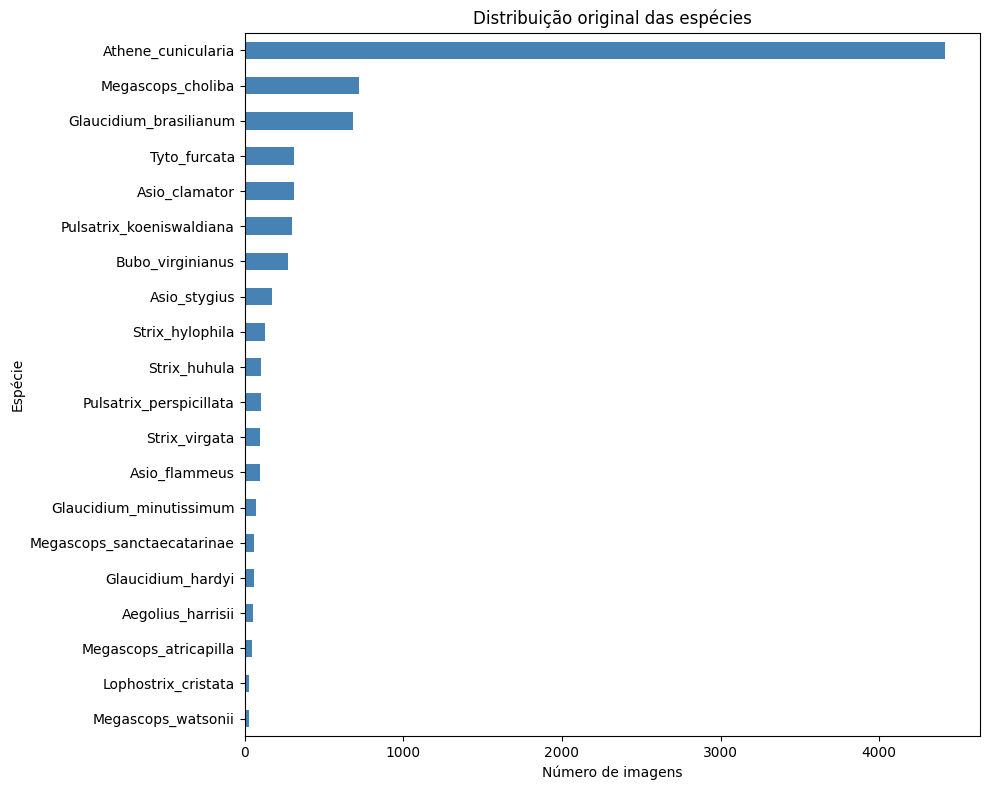

Classes: 20
Total de imagens: 8067
Megascops_watsonii              26
Lophostrix_cristata             27
Megascops_atricapilla           44
Aegolius_harrisii               55
Glaucidium_hardyi               57
Megascops_sanctaecatarinae      58
Glaucidium_minutissimum         74
Asio_flammeus                   96
Strix_virgata                   96
Pulsatrix_perspicillata        105
Strix_huhula                   106
Strix_hylophila                131
Asio_stygius                   175
Bubo_virginianus               271
Pulsatrix_koeniswaldiana       300
Asio_clamator                  310
Tyto_furcata                   312
Glaucidium_brasilianum         686
Megascops_choliba              723
Athene_cunicularia            4415


In [2]:
FILE_ID = '1fq87mnV4pG1PSV_qwWM3-IXlkWL4O6is'
DATA_DIR = Path('/content/imgs')
ZIP_PATH = Path('/content/imgs.zip')

if not DATA_DIR.is_dir():
    url = f'https://drive.google.com/uc?id={FILE_ID}'
    gdown.download(url, output=str(ZIP_PATH), quiet=False)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall('/content')
    ZIP_PATH.unlink(missing_ok=True)

if not DATA_DIR.is_dir() and Path('/content/images').is_dir():
    Path('/content/images').rename(DATA_DIR)

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f'Diretório não encontrado: {DATA_DIR}')

EXTENSOES_IMAGEM = {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}
nomes_das_classes = sorted(
    p.name for p in DATA_DIR.iterdir()
    if p.is_dir() and not p.name.startswith(('.', '__'))
)

contagem = {
    classe: sum(
        p.is_file() and p.suffix.lower() in EXTENSOES_IMAGEM
        for p in (DATA_DIR / classe).iterdir()
    )
    for classe in nomes_das_classes
}

if len(nomes_das_classes) != 20:
    raise ValueError(f'Esperava 20 classes, encontrei {len(nomes_das_classes)}')
if min(contagem.values()) < 2:
    raise ValueError(f'Classes com menos de 2 imagens: {contagem}')

contagem_serie = pd.Series(contagem, dtype='int64').sort_values()
contagem_serie.plot.barh(figsize=(10, 8), color='steelblue')
plt.title('Distribuição original das espécies')
plt.xlabel('Número de imagens')
plt.ylabel('Espécie')
plt.tight_layout()
plt.show()

print('Classes:', len(nomes_das_classes))
print('Total de imagens:', int(contagem_serie.sum()))
print(contagem_serie.to_string())


## 3. Divisão e limitação do treino

A divisão é a mesma da v2: **70% treino, 15% validação e 15% teste**, estratificada e com semente 42.

Depois da divisão, o conjunto de treino é limitado a 400 imagens por classe. A validação e o teste **não são alterados**. Isso permite comparar diretamente com os resultados da v2 no mesmo teste.

A limitação vai afetar principalmente as três classes com mais de 400 exemplos no treino. As classes menores permanecem com todas as suas imagens.


In [3]:
caminhos = []
rotulos = []
for indice, classe in enumerate(nomes_das_classes):
    arquivos = sorted(
        p for p in (DATA_DIR / classe).iterdir()
        if p.is_file() and p.suffix.lower() in EXTENSOES_IMAGEM
    )
    caminhos.extend(str(p) for p in arquivos)
    rotulos.extend([indice] * len(arquivos))

caminhos = np.asarray(caminhos)
rotulos = np.asarray(rotulos, dtype=np.int32)
num_classes = len(nomes_das_classes)

caminhos_treino, caminhos_temp, rotulos_treino, rotulos_temp = train_test_split(
    caminhos, rotulos, test_size=0.30, random_state=SEMENTE, stratify=rotulos
)
caminhos_validacao, caminhos_teste, rotulos_validacao, rotulos_teste = train_test_split(
    caminhos_temp, rotulos_temp, test_size=0.50, random_state=SEMENTE, stratify=rotulos_temp
)

def limitar_treino_por_classe(caminhos_treino, rotulos_treino, limite, semente):
    rng = np.random.default_rng(semente)
    indices_finais = []
    for classe in range(num_classes):
        indices = np.where(rotulos_treino == classe)[0]
        if len(indices) > limite:
            indices = rng.choice(indices, size=limite, replace=False)
        indices_finais.append(indices)
    indices_finais = np.concatenate(indices_finais)
    rng.shuffle(indices_finais)
    return caminhos_treino[indices_finais], rotulos_treino[indices_finais]

contagem_antes = np.bincount(rotulos_treino, minlength=num_classes)
caminhos_treino, rotulos_treino = limitar_treino_por_classe(
    caminhos_treino, rotulos_treino, LIMITE_POR_CLASSE, SEMENTE
)
contagem_depois = np.bincount(rotulos_treino, minlength=num_classes)

tabela_limites = pd.DataFrame({
    'Classe': nomes_das_classes,
    'Treino antes': contagem_antes,
    'Treino depois': contagem_depois,
})
tabela_limites['Removidas'] = tabela_limites['Treino antes'] - tabela_limites['Treino depois']
display(tabela_limites)

print('Treino antes:', int(contagem_antes.sum()))
print('Treino depois:', int(contagem_depois.sum()))
print('Classes que bateram no limite:')
print(tabela_limites.loc[tabela_limites['Removidas'] > 0, ['Classe', 'Removidas']].to_string(index=False))

AUTOTUNE = tf.data.AUTOTUNE

def carregar_imagem(caminho, rotulo):
    bytes_imagem = tf.io.read_file(caminho)
    imagem = tf.io.decode_image(bytes_imagem, channels=3, expand_animations=False)
    imagem = tf.image.resize(imagem, TAMANHO_IMAGEM, antialias=True)
    imagem.set_shape((*TAMANHO_IMAGEM, 3))
    return imagem, rotulo

def criar_dataset(caminhos_conjunto, rotulos_conjunto, treinamento=False):
    ds = tf.data.Dataset.from_tensor_slices((caminhos_conjunto, rotulos_conjunto))
    ds = ds.map(carregar_imagem, num_parallel_calls=AUTOTUNE)
    if treinamento:
        ds = ds.shuffle(
            buffer_size=min(len(caminhos_conjunto), 4096),
            seed=SEMENTE,
            reshuffle_each_iteration=True,
        )
    return ds.batch(TAMANHO_LOTE).prefetch(AUTOTUNE)

dataset_treino = criar_dataset(caminhos_treino, rotulos_treino, treinamento=True)
dataset_validacao = criar_dataset(caminhos_validacao, rotulos_validacao)
dataset_teste = criar_dataset(caminhos_teste, rotulos_teste)

print('Validação:', len(caminhos_validacao))
print('Teste:', len(caminhos_teste))

# Pesos balanceados completos após a limitação do treino.
pesos = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(num_classes),
    y=rotulos_treino,
)
pesos_das_classes = {int(i): float(w) for i, w in enumerate(pesos)}

tabela_pesos = pd.DataFrame({
    'Classe': nomes_das_classes,
    'Treino depois': contagem_depois,
    'Peso': pesos,
}).sort_values('Peso', ascending=False)
display(tabela_pesos)

print('Menor peso:', round(min(pesos_das_classes.values()), 3))
print('Maior peso:', round(max(pesos_das_classes.values()), 3))


,Classe,Treino antes,Treino depois,Removidas
0,Aegolius_harrisii,39,39,0
1,Asio_clamator,217,217,0
2,Asio_flammeus,67,67,0
3,Asio_stygius,122,122,0
4,Athene_cunicularia,3090,400,2690
5,Bubo_virginianus,190,190,0
6,Glaucidium_brasilianum,480,400,80
7,Glaucidium_hardyi,40,40,0
8,Glaucidium_minutissimum,52,52,0
9,Lophostrix_cristata,19,19,0


Treino antes: 5646
Treino depois: 2770
Classes que bateram no limite:
                Classe  Removidas
    Athene_cunicularia       2690
Glaucidium_brasilianum         80
     Megascops_choliba        106
Validação: 1210
Teste: 1211


,Classe,Treino depois,Peso
13,Megascops_watsonii,18,7.694444
9,Lophostrix_cristata,19,7.289474
10,Megascops_atricapilla,31,4.467742
0,Aegolius_harrisii,39,3.551282
7,Glaucidium_hardyi,40,3.462500
12,Megascops_sanctaecatarinae,41,3.378049
8,Glaucidium_minutissimum,52,2.663462
2,Asio_flammeus,67,2.067164
18,Strix_virgata,67,2.067164
15,Pulsatrix_perspicillata,73,1.897260


Menor peso: 0.346
Maior peso: 7.694


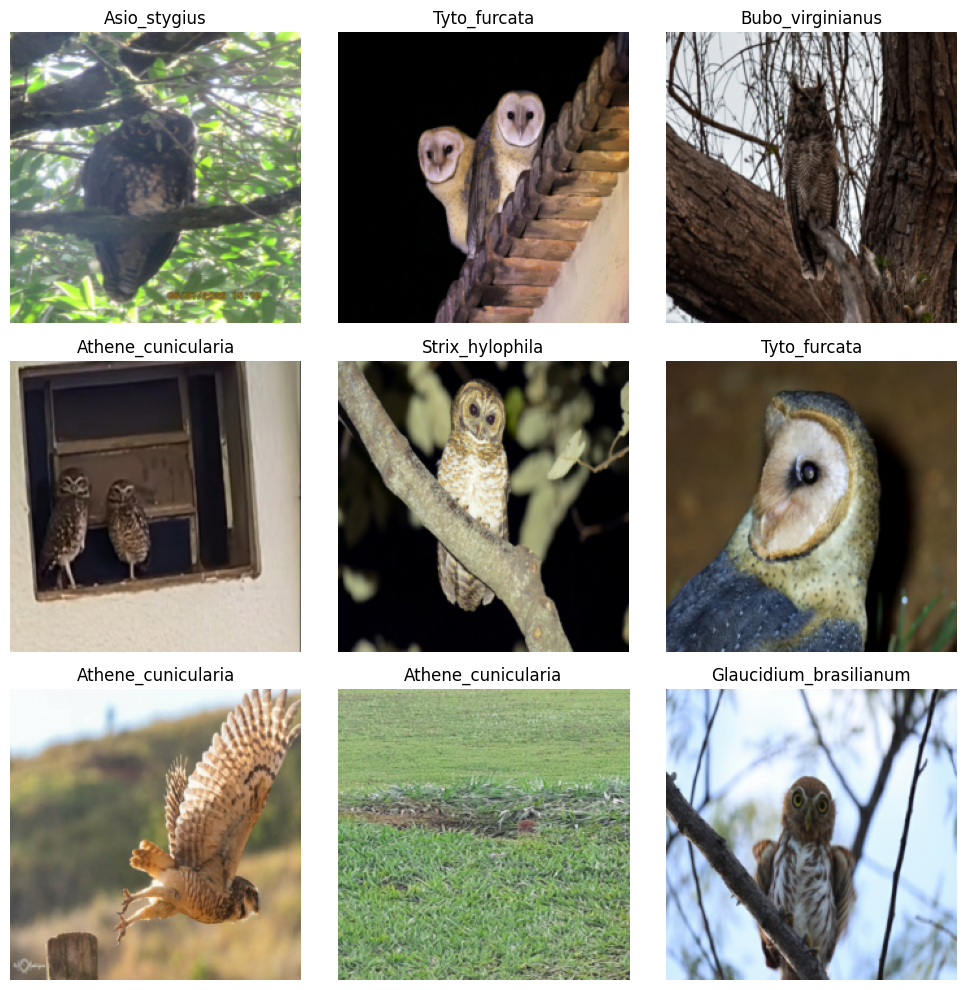

In [4]:
plt.figure(figsize=(10, 10))
for imagens, rotulos_lote in dataset_treino.take(1):
    for i in range(min(9, len(imagens))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(imagens[i].numpy().astype('uint8'))
        plt.title(nomes_das_classes[int(rotulos_lote[i])])
        plt.axis('off')
plt.tight_layout()
plt.show()


## 4. Arquitetura própria

A arquitetura é a mesma família da v2, mas com dropout menor para combater o subajuste:

- 4 blocos convolucionais;
- 2 convoluções 3×3 por bloco;
- filtros 32 → 64 → 128 → 256;
- BatchNorm;
- MaxPooling;
- Dropout de 0,10 a 0,25;
- GlobalAveragePooling;
- Dense 128;
- Dropout final 0,30;
- Softmax de 20 classes.


In [5]:
def criar_cnn(num_classes):
    entradas = layers.Input(shape=(*TAMANHO_IMAGEM, 3), name='imagem')

    x = layers.RandomFlip('horizontal')(entradas)
    x = layers.RandomRotation(0.08, fill_mode='reflect')(x)
    x = layers.RandomZoom(0.10, fill_mode='reflect')(x)
    x = layers.RandomContrast(0.10)(x)
    x = layers.Rescaling(1.0 / 255.0, name='normalizacao')(x)

    for filtros, dropout in [(32, 0.10), (64, 0.15), (128, 0.20), (256, 0.25)]:
        for _ in range(2):
            x = layers.Conv2D(
                filtros, 3, padding='same', use_bias=False,
                kernel_initializer='he_normal'
            )(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Dropout(dropout)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.30)(x)
    saidas = layers.Dense(num_classes, activation='softmax', name='especie')(x)
    return models.Model(entradas, saidas, name='cnn_corujas_v3')


modelo = criar_cnn(num_classes)
modelo.summary()


Model: "cnn_corujas_v3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacao (Rescaling)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             

 Total params: 1,210,612 (4.62 MB)

 Trainable params: 1,208,692 (4.61 MB)

 Non-trainable params: 1,920 (7.50 KB)

## 5. Treinamento

A seleção do melhor modelo é feita por **F1 macro na validação**. O `ReduceLROnPlateau` também monitora essa métrica, para não reduzir a taxa de aprendizado enquanto o F1 ainda estiver melhorando.

Nenhum checkpoint é salvo em disco: o `EarlyStopping` restaura os melhores pesos na memória.


In [6]:
class MetricasValidacao(callbacks.Callback):
    def __init__(self, dataset, rotulos):
        super().__init__()
        self.dataset = dataset
        self.rotulos = np.asarray(rotulos)
        self.f1_hist = []
        self.balanced_hist = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        probabilidades = self.model.predict(self.dataset, verbose=0)
        previstos = np.argmax(probabilidades, axis=1)
        f1 = float(f1_score(self.rotulos, previstos, average='macro', zero_division=0))
        bal = float(balanced_accuracy_score(self.rotulos, previstos))
        logs['val_f1_macro'] = f1
        logs['val_balanced_accuracy'] = bal
        self.f1_hist.append(f1)
        self.balanced_hist.append(bal)


modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

cb_metricas = MetricasValidacao(dataset_validacao, rotulos_validacao)
inicio_treino = time.perf_counter()
history = modelo.fit(
    dataset_treino,
    validation_data=dataset_validacao,
    epochs=EPOCAS,
    class_weight=pesos_das_classes,
    callbacks=[
        cb_metricas,
        callbacks.EarlyStopping(
            monitor='val_f1_macro',
            mode='max',
            patience=8,
            restore_best_weights=True,
        ),
        callbacks.ReduceLROnPlateau(
            monitor='val_f1_macro',
            mode='max',
            factor=0.5,
            patience=3,
            min_lr=1e-6,
            verbose=1,
        ),
    ],
    verbose=2,
)
tempo_treino = time.perf_counter() - inicio_treino

melhor_epoca = int(np.argmax(cb_metricas.f1_hist) + 1)
melhor_f1 = float(max(cb_metricas.f1_hist))
print('Tempo de treino: %.1f s' % tempo_treino)
print('Melhor época:', melhor_epoca)
print('Melhor F1 macro de validação: %.4f' % melhor_f1)


Epoch 1/50
87/87 - 46s - 531ms/step - accuracy: 0.0755 - loss: 2.9945 - val_accuracy: 0.0140 - val_loss: 6.8556 - val_f1_macro: 0.0122 - val_balanced_accuracy: 0.0432 - learning_rate: 0.0010
Epoch 2/50
87/87 - 21s - 244ms/step - accuracy: 0.0982 - loss: 2.8205 - val_accuracy: 0.1686 - val_loss: 3.0970 - val_f1_macro: 0.0400 - val_balanced_accuracy: 0.0805 - learning_rate: 0.0010
Epoch 3/50
87/87 - 21s - 243ms/step - accuracy: 0.1292 - loss: 2.7675 - val_accuracy: 0.0207 - val_loss: 6.1040 - val_f1_macro: 0.0129 - val_balanced_accuracy: 0.0745 - learning_rate: 0.0010
Epoch 4/50
87/87 - 21s - 244ms/step - accuracy: 0.1361 - loss: 2.7424 - val_accuracy: 0.1711 - val_loss: 2.4856 - val_f1_macro: 0.0415 - val_balanced_accuracy: 0.1292 - learning_rate: 0.0010
Epoch 5/50
87/87 - 21s - 244ms/step - accuracy: 0.1245 - loss: 2.7121 - val_accuracy: 0.2099 - val_loss: 2.5093 - val_f1_macro: 0.0545 - val_balanced_accuracy: 0.1197 - learning_rate: 0.0010
Epoch 6/50
87/87 - 21s - 244ms/step - accurac

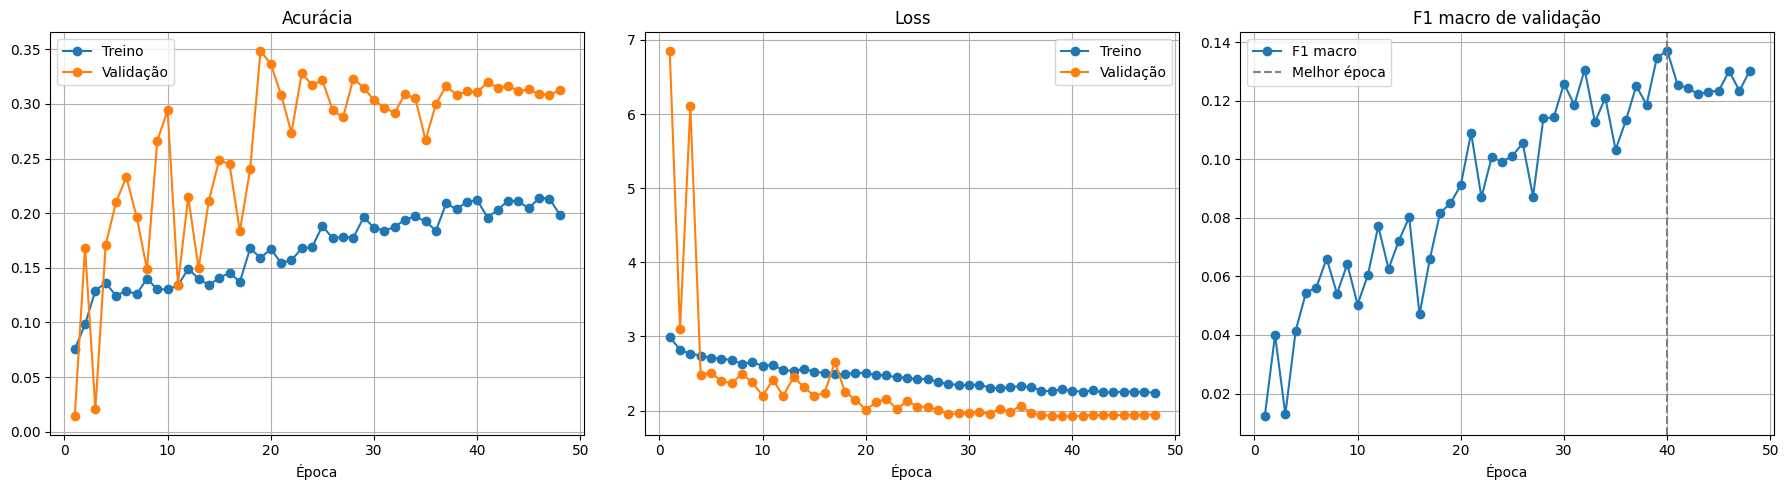

In [7]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epocas = range(1, len(acc) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(epocas, acc, label='Treino', marker='o')
axes[0].plot(epocas, val_acc, label='Validação', marker='o')
axes[0].set_title('Acurácia')
axes[0].set_xlabel('Época')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epocas, loss, label='Treino', marker='o')
axes[1].plot(epocas, val_loss, label='Validação', marker='o')
axes[1].set_title('Loss')
axes[1].set_xlabel('Época')
axes[1].legend()
axes[1].grid(True)

axes[2].plot(range(1, len(cb_metricas.f1_hist) + 1), cb_metricas.f1_hist, label='F1 macro', marker='o')
axes[2].axvline(melhor_epoca, color='gray', linestyle='--', label='Melhor época')
axes[2].set_title('F1 macro de validação')
axes[2].set_xlabel('Época')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()


## 6. Avaliação no teste

O teste é o mesmo da v2. A comparação principal é:

- a acurácia global pode cair, porque a classe majoritária foi limitada no treino;
- o F1 macro e o recall das espécies raras devem ser observados com prioridade.

Também mostramos o recall por classe e destacamos as espécies com recall zero ou muito baixo.


loss_teste: 1.9627
acuracia_teste: 0.3146
acuracia_balanceada: 0.2067
precisao_macro: 0.1252
recall_macro: 0.2067
f1_macro: 0.1174

Relatório por espécie:
                            precision    recall  f1-score   support

         Aegolius_harrisii      0.077     0.250     0.118         8
             Asio_clamator      0.064     0.064     0.064        47
             Asio_flammeus      0.032     0.571     0.061        14
              Asio_stygius      0.176     0.111     0.136        27
        Athene_cunicularia      0.838     0.454     0.589       663
          Bubo_virginianus      0.176     0.366     0.238        41
    Glaucidium_brasilianum      0.441     0.146     0.219       103
         Glaucidium_hardyi      0.030     0.125     0.049         8
   Glaucidium_minutissimum      0.121     0.364     0.182        11
       Lophostrix_cristata      0.000     0.000     0.000         4
     Megascops_atricapilla      0.000     0.000     0.000         6
         Megascops_choliba  

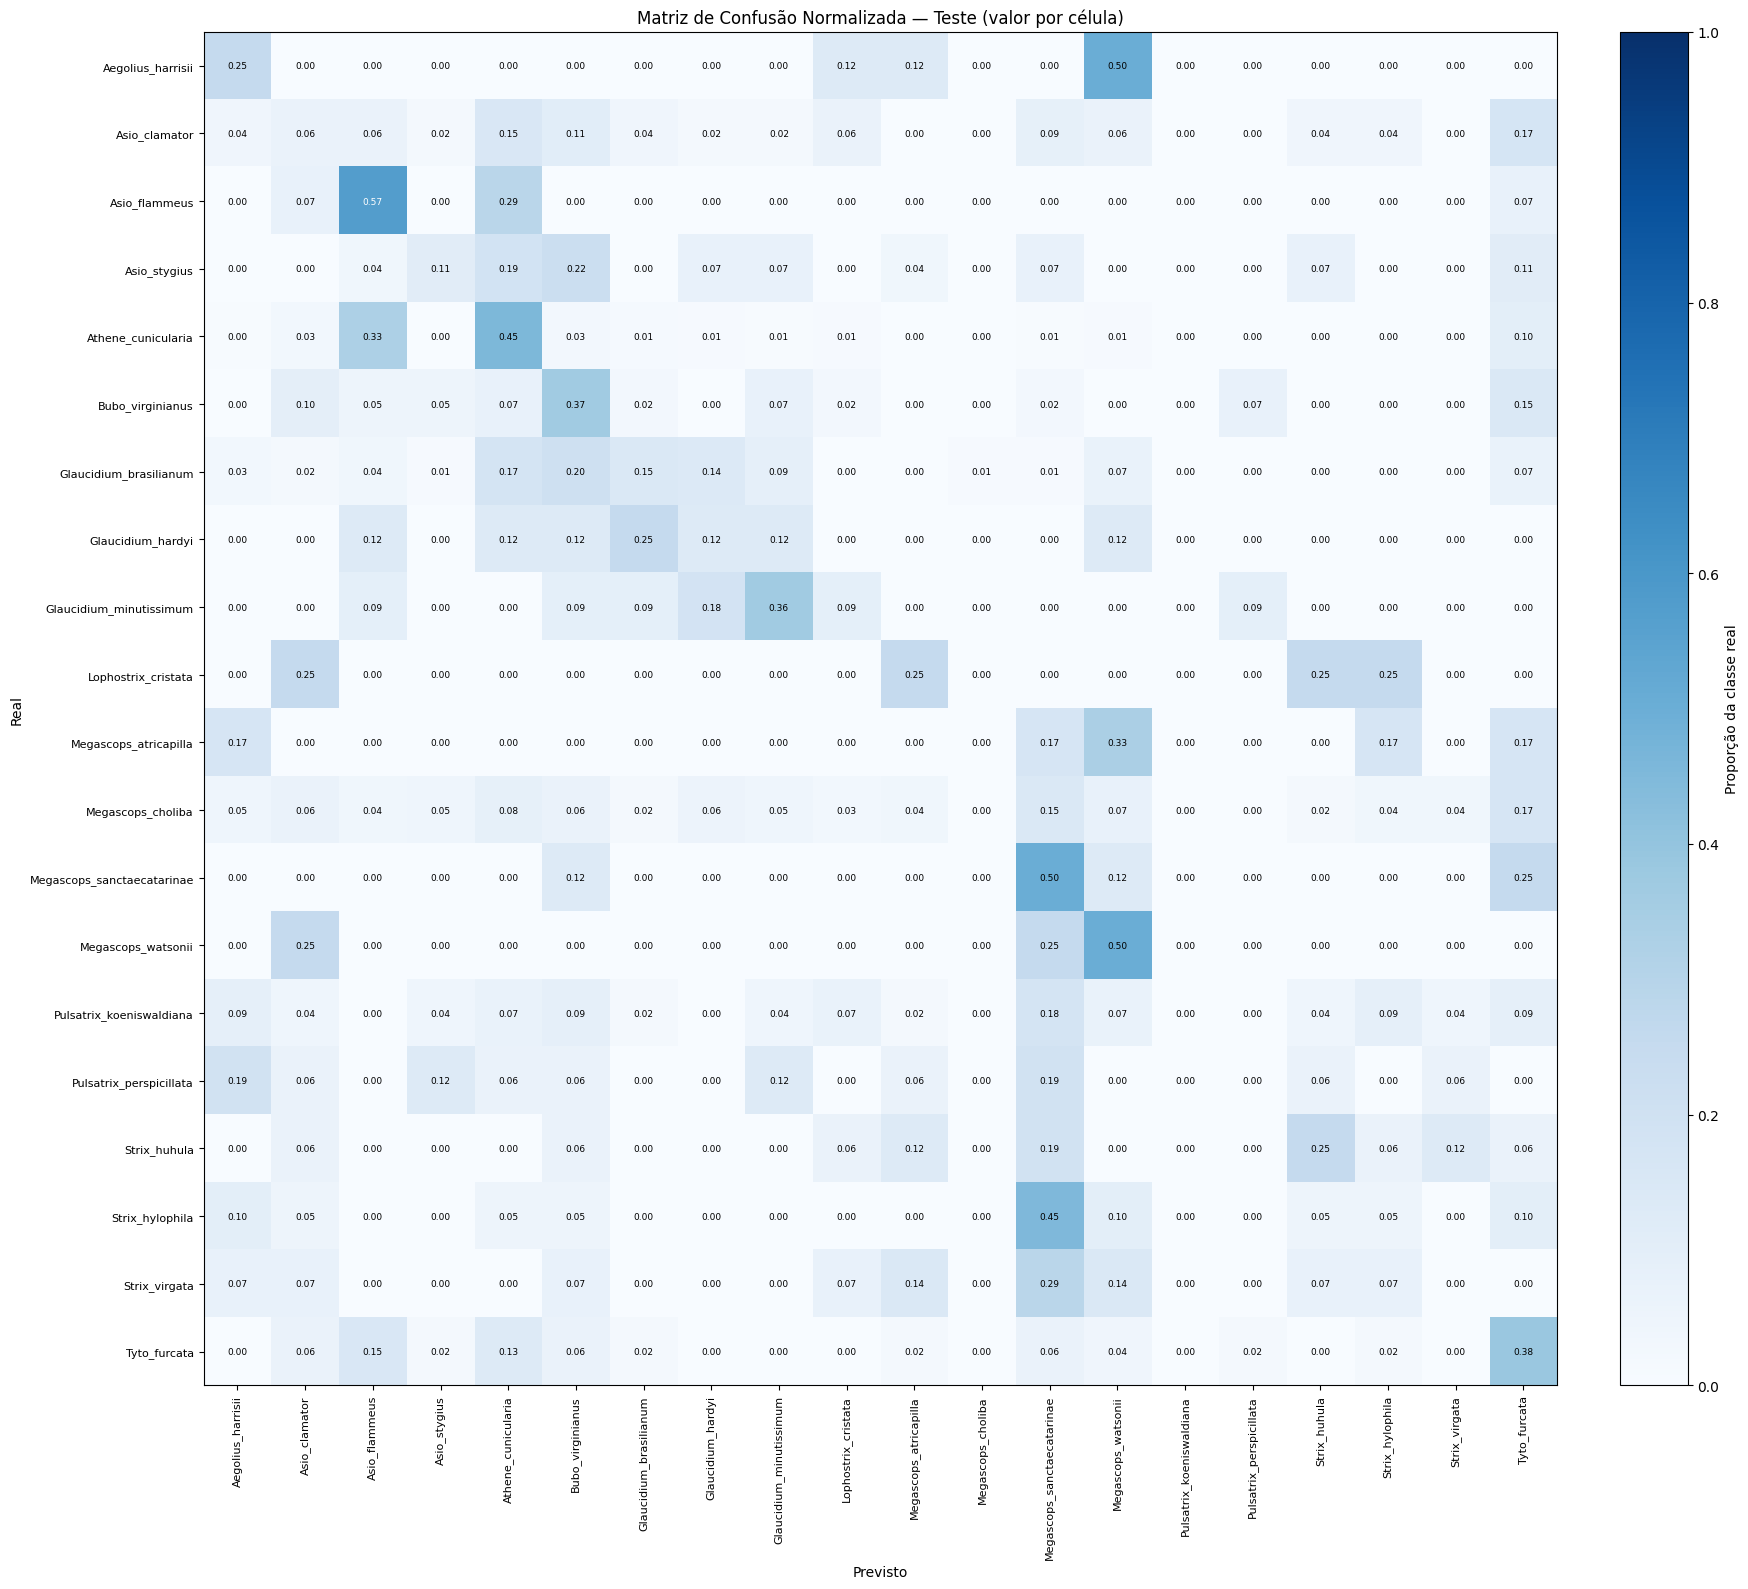

In [8]:
perda_teste, acuracia_keras = modelo.evaluate(dataset_teste, verbose=0)
probabilidades = modelo.predict(dataset_teste, verbose=0)
y_reais = np.asarray(rotulos_teste)
y_previstos = np.argmax(probabilidades, axis=1)

metricas = {
    'loss_teste': float(perda_teste),
    'acuracia_teste': float(accuracy_score(y_reais, y_previstos)),
    'acuracia_balanceada': float(balanced_accuracy_score(y_reais, y_previstos)),
    'precisao_macro': float(precision_score(y_reais, y_previstos, average='macro', zero_division=0)),
    'recall_macro': float(recall_score(y_reais, y_previstos, average='macro', zero_division=0)),
    'f1_macro': float(f1_score(y_reais, y_previstos, average='macro', zero_division=0)),
}

for nome, valor in metricas.items():
    print(f'{nome}: {valor:.4f}')

print('\nRelatório por espécie:')
print(classification_report(
    y_reais,
    y_previstos,
    labels=np.arange(num_classes),
    target_names=nomes_das_classes,
    digits=3,
    zero_division=0,
))

cm = confusion_matrix(
    y_reais,
    y_previstos,
    labels=np.arange(num_classes),
    normalize='true',
)

fig, ax = plt.subplots(figsize=(18, 16))
im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)

ax.set_xticks(np.arange(num_classes))
ax.set_yticks(np.arange(num_classes))
ax.set_xticklabels(nomes_das_classes, rotation=90, fontsize=8)
ax.set_yticklabels(nomes_das_classes, fontsize=8)
ax.set_xlabel('Previsto')
ax.set_ylabel('Real')
ax.set_title('Matriz de Confusão Normalizada — Teste (valor por célula)')

for i in range(num_classes):
    for j in range(num_classes):
        valor = cm[i, j]
        ax.text(
            j, i, f'{valor:.2f}',
            ha='center', va='center', fontsize=6.5,
            color='white' if valor > 0.55 else 'black'
        )

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Proporção da classe real')
plt.tight_layout()
plt.show()


,Classe,Suporte no teste,Recall
15,Pulsatrix_perspicillata,16,0.000
11,Megascops_choliba,109,0.000
10,Megascops_atricapilla,6,0.000
14,Pulsatrix_koeniswaldiana,45,0.000
9,Lophostrix_cristata,4,0.000
18,Strix_virgata,14,0.000
17,Strix_hylophila,20,0.050
1,Asio_clamator,47,0.064
3,Asio_stygius,27,0.111
7,Glaucidium_hardyi,8,0.125


Classes com recall zero: ['Pulsatrix_perspicillata', 'Megascops_choliba', 'Megascops_atricapilla', 'Pulsatrix_koeniswaldiana', 'Lophostrix_cristata', 'Strix_virgata']
Classes com recall < 10%: ['Pulsatrix_perspicillata', 'Megascops_choliba', 'Megascops_atricapilla', 'Pulsatrix_koeniswaldiana', 'Lophostrix_cristata', 'Strix_virgata', 'Strix_hylophila', 'Asio_clamator']


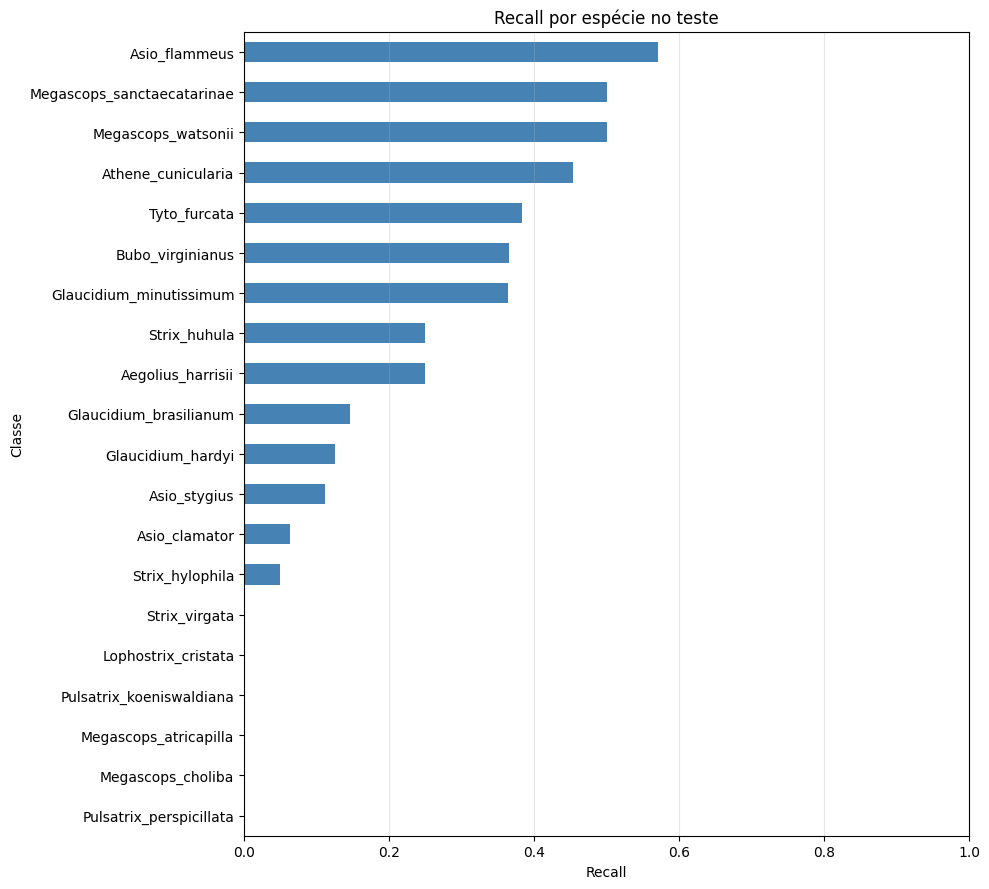

In [9]:
recall_classes = recall_score(
    y_reais, y_previstos, labels=np.arange(num_classes),
    average=None, zero_division=0
)
suporte = np.bincount(y_reais, minlength=num_classes)

tabela_recall = pd.DataFrame({
    'Classe': nomes_das_classes,
    'Suporte no teste': suporte,
    'Recall': recall_classes,
}).sort_values('Recall')

display(tabela_recall.round(3))

sem_recall = tabela_recall.loc[tabela_recall['Recall'] == 0, 'Classe'].tolist()
baixo_recall = tabela_recall.loc[tabela_recall['Recall'] < 0.10, 'Classe'].tolist()

print('Classes com recall zero:', sem_recall if sem_recall else 'nenhuma')
print('Classes com recall < 10%:', baixo_recall if baixo_recall else 'nenhuma')

tabela_recall.set_index('Classe')['Recall'].plot.barh(
    figsize=(10, 9), color='steelblue'
)
plt.title('Recall por espécie no teste')
plt.xlabel('Recall')
plt.xlim(0, 1)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Demonstração dentro do Colab

O modelo permanece na memória da sessão. Não há salvamento no Drive. A célula abaixo permite enviar uma imagem e ver o top-3.


In [ ]:
from google.colab import files
from PIL import Image, ImageOps
from IPython.display import display

def prever(caminho):
    imagem = ImageOps.exif_transpose(Image.open(caminho)).convert('RGB')
    imagem = imagem.resize(TAMANHO_IMAGEM, Image.Resampling.BILINEAR)
    x = np.asarray(imagem, dtype=np.float32)
    # O modelo já contém o pré-processamento. Não aplique preprocess_input aqui.
    probs = modelo.predict(x[None, ...], verbose=0)[0]
    ordem = np.argsort(probs)[-3:][::-1]
    return [(nomes_das_classes[i], float(probs[i])) for i in ordem]

enviados = files.upload()
for nome in enviados:
    display(Image.open(nome).convert('RGB'))
    print(f'Imagem: {nome}')
    resultados = prever(nome)
    for classe, prob in resultados:
        print(f'  {classe}: {prob:.2%}')
    if resultados[0][1] < 0.5:
        print('  Aviso: confiança baixa; a imagem pode não ser uma das 20 espécies.')


## 8. Conclusão

Esta V3 testa uma hipótese clara:

> Limitar a classe majoritária no treino e aumentar o peso das classes raras melhora o recall das espécies que hoje têm retorno zero?

O que observar no resultado:

1. **F1 macro** deve aumentar se o balanceamento funcionar.
2. **Acurácia balanceada** deve acompanhar.
3. **Recall das classes raras** deve sair de zero.
4. **Acurácia global** pode cair; isso não significa necessariamente que o modelo piorou para o objetivo de identificar todas as espécies.
5. Se muitas classes continuarem com recall zero, o gargalo é a quantidade de dados, não apenas o balanceamento.

Nada foi salvo no Drive. Se a sessão do Colab for encerrada, o modelo e os resultados em memória serão perdidos.
